# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to six slides (one for each of the topics/questions in the 'Get to work!' section); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

## Design decisions and why

For the oral and the blog post. Edit here if a choice changes.

| Topic | Decision | Reason |
|---|---|---|
| Dataset | IMDB (`mteb/imdb`): 24,904 training reviews, 2 classes, about 50/50 (12,432 negative / 12,472 positive). | Balanced labels, so accuracy is a fair main metric; macro recall and macro F1 are reported as well. |
| Preprocessing | Strip HTML tags, decode HTML entities, collapse whitespace, lowercase except ALL-CAPS words; original text kept in `text_original`. | Removes markup noise (e.g. `<br />`) while keeping emphasis such as AWFUL as a distinct token. |
| Validation / test | 2,000 random reviews from the original IMDB test split (seed 0) are the validation set; the other 22,678 are the new test set. | Hyperparameter tuning needs data that is neither training nor final test. Indices saved in `results/sentiment/`. The new test set is not used for tuning. |
| Tokenizer | One BPE tokenizer trained on the preprocessed training reviews only, vocab size 5000, min frequency 2, shared by all representations. | Same tokens for every representation, so they differ only in weighting. Vocab 5000 won on the validation set (logistic + bag-of-words): 1000 → 0.8245, 5000 → 0.8580, 8000 → 0.8510, 16000 → 0.8550. The standard error is about 0.8 points, so 5000, 8000 and 16000 are practically tied; ties go to the smaller vocabulary. Trained on IMDB itself (no larger external corpus). |
| Representations | Token indicators and bag-of-words (tutorial) plus TF-IDF. | TF-IDF down-weights tokens that occur in many reviews and L2-normalises, removing the effect of review length. Implemented with scikit-learn's `TfidfVectorizer` over BPE token ids (not hand-written); idf is fit on all training reviews (label-free; mild leakage across CV folds). |
| Architectures | Log-linear (scikit-learn saga, `max_iter=100`) and one-hidden-layer MLP (128 hidden, dropout 0.1, batch 64, lr 1e-4, weight decay 1e-4), as in the tutorial. | Tutorial systems are rerun on the new data with the tutorial's hyperparameters, so they are the baseline. Logistic runs are seeded (`random_state`). |
| MLP epochs | Up to 50 epochs with early stopping (patience 5, min_delta 0.001 on validation loss); best-validation-loss checkpoint kept. | Our folds have ~19.9k reviews (~312 steps per epoch) vs ~96k per tutorial fold (~1,500 steps per epoch), so 10 epochs would be ~3k steps vs ~15k; 50 epochs is ~15.6k steps. Caveat: checkpoint and stopping point are chosen on the fold being scored (mildly optimistic, the same for all MLPs). |
| Cross-validation | 5 folds, seeds 42 and 67 (two runs with different fold shuffles); every system uses exactly the same folds; training reviews only. | The Bayesian correlated t-test pairs folds, so splits must match across systems. Two runs give 10 paired measurements per system. |
| Metrics | Accuracy (main), macro recall, macro F1 per validation fold; predictions and validation ids saved for error analysis. | Balanced classes. For two classes macro recall equals balanced accuracy. |
| Reproducibility | Fixed seeds; results saved per system and seed in `results/sentiment/` (re-running a cell loads saved results); small artefacts are git-tracked, model files are not. | Experiments are shared with the blog post and reused in projects 2 and 3. |

**Still open:**
- ROPE size for the Bayesian comparison (tutorial used 0.005) and its motivation.
- Our own architecture for the third column of the 3x3 grid.
- Whether to add more seeds or evaluate the final systems on the new test set.


# Load dataset 

In [1]:
import pandas as pd


splits = {'train': 'data/train-00000-of-00001.parquet', 'test': 'data/test-00000-of-00001.parquet'}
df = pd.read_parquet("hf://datasets/mteb/imdb/" + splits["train"])

In [2]:
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
}))

print(f"Reviews: {len(df):,}")
print(f"Duplicate review texts: {df['text'].duplicated().sum():,}")
print(f"Empty reviews: {df['text'].fillna('').str.strip().eq('').sum():,}")

class_balance = (
    df.groupby(["label", "label_text"])
    .size()
    .rename("count")
    .to_frame()
)
class_balance["percent"] = (100 * class_balance["count"] / len(df)).round(2)
display(class_balance)

,dtype,missing
text,str,0
label,int64,0
label_text,str,0


Reviews: 24,904
Duplicate review texts: 0
Empty reviews: 0


,,count,percent
label,label_text,,
0,negative,12432,49.92
1,positive,12472,50.08


characters                    words                 
                mean median min    max   mean median min   max
sentiment                                                     
negative      1304.2  977.0  52   8969  231.1  175.0  10  1522
positive      1348.5  982.0  70  13704  236.9  174.0  12  2470

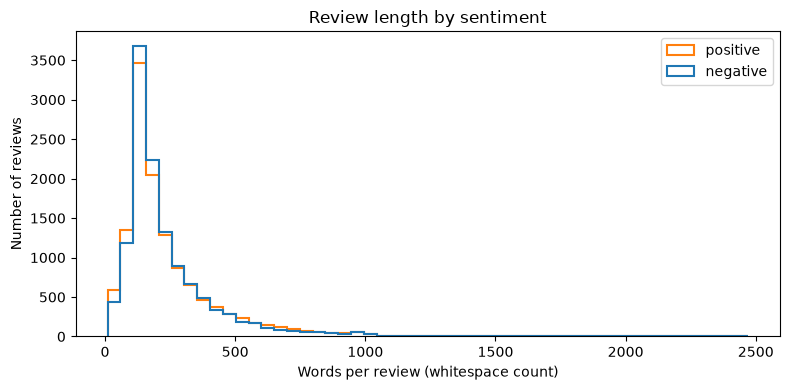

In [3]:
import matplotlib.pyplot as plt

review_lengths = pd.DataFrame({
    "sentiment": df["label_text"],
    "characters": df["text"].fillna("").str.len(),
    "words": df["text"].fillna("").str.split().str.len(),
})

display(
    review_lengths.groupby("sentiment")[["characters", "words"]]
    .agg(["mean", "median", "min", "max"])
    .round(1)
)

groups = list(review_lengths.groupby("sentiment"))
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(
    [group["words"] for _, group in groups],
    bins=50,
    histtype="step",
    linewidth=1.5,
    label=[sentiment for sentiment, _ in groups],
)
ax.set(
    title="Review length by sentiment",
    xlabel="Words per review (whitespace count)",
    ylabel="Number of reviews",
)
ax.legend()
plt.tight_layout()
plt.show()

In [4]:
# Inspect the shortest and longest cleaned reviews by whitespace word count.
review_sizes = df[["text", "label_text"]].assign(
    word_count=df["text"].fillna("").str.split().str.len()
)

for title, reviews in [
    ("5 shortest reviews", review_sizes.nsmallest(5, "word_count")),
    ("5 longest reviews", review_sizes.nlargest(5, "word_count")),
]:
    print(f"\n{title}\n" + "=" * len(title))
    for index, row in reviews.iterrows():
        print(f"\nRow {index} | {row['label_text']} | {row['word_count']} words")
        print(row["text"])


5 shortest reviews

Row 2401 | negative | 10 words
I wouldn't rent this one even on dollar rental night.

Row 10872 | negative | 10 words
This movie is terrible but it has some good effects.

Row 372 | negative | 11 words
You'd better choose Paul Verhoeven's even if you have watched it.

Row 12053 | negative | 12 words
Ming The Merciless does a little Bardwork and a movie most foul!

Row 16993 | positive | 12 words
Adrian Pasdar is excellent is this film. He makes a fascinating woman.

5 longest reviews

Row 13685 | positive | 2470 words
Match 1: Tag Team Table Match Bubba Ray and Spike Dudley vs Eddie Guerrero and Chris Benoit Bubba Ray and Spike Dudley started things off with a Tag Team Table Match against Eddie Guerrero and Chris Benoit. According to the rules of the match, both opponents have to go through tables in order to get the win. Benoit and Guerrero heated up early on by taking turns hammering first Spike and then Bubba Ray. A German suplex by Benoit to Bubba took the wind

We replace HTML tags with spaces, decode HTML entities, and collapse repeated whitespace. Words are lowercased (e.g., `Read` → `read`), except all-caps words such as `AWFUL`, which retain their emphasis. The original reviews are preserved in `text_original`, while `text` contains the normalized reviews.

In [5]:
import re
from html.parser import HTMLParser


class ReviewHTMLParser(HTMLParser):
    def __init__(self):
        super().__init__(convert_charrefs=True)
        self.parts = []

    def handle_starttag(self, tag, attrs):
        self.parts.append(" ")

    def handle_endtag(self, tag):
        self.parts.append(" ")

    def handle_data(self, data):
        self.parts.append(data)


def normalize_review(text):
    parser = ReviewHTMLParser()
    parser.feed(text)
    parser.close()
    text = "".join(parser.parts)
    text = re.sub(
        r"[^\W\d_]+(?:['’][^\W\d_]+)*",
        lambda match: match[0] if match[0].isupper() else match[0].lower(),
        text,
    )
    return " ".join(text.split())


if "text_original" not in df.columns:
    df["text_original"] = df["text"].copy()
df["text"] = df["text_original"].map(normalize_review, na_action="ignore")
display(df[["text_original", "text"]].head(3))


,text_original,text
0,I rented I AM CURIOUS-YELLOW from my video sto...,I rented I AM CURIOUS-YELLOW from my video sto...
1,"""I Am Curious: Yellow"" is a risible and preten...","""I am curious: yellow"" is a risible and preten..."
2,If only to avoid making this type of film in t...,if only to avoid making this type of film in t...


## Validation and test sets

We hold out **2,000 random reviews from the original IMDB test split** as a validation set for tuning (the BPE vocabulary size below). The remaining test reviews form the **new test set** (`df_test`), which is never used for tuning. Both are preprocessed with the same `normalize_review` as the training data, and the original test-row indices of both sets are saved in `results/sentiment/` so the split is reproducible.

In [16]:
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 0
N_VALIDATION = 2000

df_test_original = pd.read_parquet("hf://datasets/mteb/imdb/" + splits["test"])

# Validation: 2,000 random test reviews. New test set: all the other test reviews.
# Both keep the original test-row index, so they can be traced back to the source split.
df_val = df_test_original.sample(n=N_VALIDATION, random_state=SEED).sort_index()
df_test = df_test_original.drop(index=df_val.index)

# Same preprocessing as the training reviews (normalize_review comes from the preprocessing cell).
df_val = df_val.assign(text_original=df_val["text"], text=df_val["text"].map(normalize_review))
df_test = df_test.assign(text_original=df_test["text"], text=df_test["text"].map(normalize_review))

split_dir = Path("results/sentiment")
split_dir.mkdir(parents=True, exist_ok=True)
np.save(split_dir / "validation_test_indices.npy", df_val.index.to_numpy())
np.save(split_dir / "new_test_indices.npy", df_test.index.to_numpy())

# Sanity checks: nothing lost, no overlap, balanced labels, no train/validation/test text leakage.
assert len(df_val) + len(df_test) == len(df_test_original)
assert df_val.index.intersection(df_test.index).empty
train_texts = set(df["text"])
print(f"Train: {len(df):,} | validation: {len(df_val):,} | new test: {len(df_test):,}")
for name, part in [("validation", df_val), ("new test", df_test)]:
    print(f"{name}: labels {part['label'].value_counts().sort_index().to_dict()}, "
          f"texts also in train: {part['text'].isin(train_texts).sum()}")
print(f"texts in both validation and new test: {df_val['text'].isin(set(df_test['text'])).sum()}")


Train: 24,904 | validation: 2,000 | new test: 22,678
validation: labels {0: 974, 1: 1026}, texts also in train: 0
new test: labels {0: 11292, 1: 11386}, texts also in train: 0
texts in both validation and new test: 0


## Choosing the BPE vocabulary size

We choose the vocabulary size on the 2,000-review validation set prepared above. For each candidate size we train a BPE tokenizer on the preprocessed training reviews, fit the tutorial's logistic regression (saga, `max_iter=100`) on bag-of-words counts of the training reviews, and measure accuracy on the validation reviews. Only the vocabulary size changes between runs. The best size is then used for the tokenizer in the rest of the notebook.

Notes for the oral:
- Accuracy is fine as the metric because the labels are balanced (about 50/50).
- With 2,000 reviews the standard error of an accuracy near 0.88 is about 0.7 points, so differences smaller than that are not meaningful; ties go to the smaller vocabulary.
- The bag-of-words matrix is built sparsely here (same counts as the tutorial's `BagOfWords`) because `loglin.fit` builds a dense matrix first, which would need several GB at vocabulary 16,000.
- Only the results table (`results/sentiment/vocab_size_tuning.csv`) is saved; the candidate tokenizers and logistic models are discarded. Only the chosen tokenizer is trained and saved, in the next section.

In [ ]:
# THIS IS COMMENTED OUT TO NOT ALWAYS RUN THE HYPERPARAMTER TUNNING. IF YOU WANT, YOU CAN RUN IT AND SEE THAT 5000 IS THE BEST

# import sys
# import warnings
# from pathlib import Path

# import numpy as np
# import pandas as pd
# from scipy.sparse import csr_matrix
# from sklearn.exceptions import ConvergenceWarning
# from sklearn.linear_model import LogisticRegression

# sys.path.insert(0, str(Path.cwd().parent))  # run with part1/ as working directory
# import part1

# # Uses df (train), df_val (validation) and SEED from the cells above.
# CANDIDATE_VOCAB_SIZES = [1000, 5000, 8000, 16000]
# TOKENIZER_MIN_FREQ = 2  # held fixed; only the vocabulary size is tuned


# def bow_matrix(tokenizer, texts):
#     """Bag-of-words counts (one column per BPE token) as a sparse matrix.

#     Same representation as the tutorial's BagOfWords, but built sparsely: loglin.fit goes through
#     a dense matrix, which is about 6 GB at vocabulary 16,000 and 25k reviews.
#     """
#     rows, cols, vals = [], [], []
#     for i, enc in enumerate(tokenizer.encode_batch(list(texts))):
#         ids, counts = np.unique(enc.ids, return_counts=True)
#         rows.append(np.full(len(ids), i))
#         cols.append(ids)
#         vals.append(counts)
#     return csr_matrix(
#         (np.concatenate(vals).astype(np.float64), (np.concatenate(rows), np.concatenate(cols))),
#         shape=(len(texts), len(tokenizer.get_vocab())),
#     )


# # --- One tokenizer + one logistic regression per candidate size; everything else is fixed ---
# y_train, y_val = df["label"].to_numpy(), df_val["label"].to_numpy()
# vocab_results = []
# for vocab_size in CANDIDATE_VOCAB_SIZES:
#     candidate = part1.experiment.train_tokenizer(
#         df["text"].tolist(), vocab_size=vocab_size, min_frequency=TOKENIZER_MIN_FREQ
#     )
#     X_train, X_val = bow_matrix(candidate, df["text"]), bow_matrix(candidate, df_val["text"])

#     # Same settings as loglin.fit, plus a fixed random_state: saga shuffles the data, so without it
#     # the accuracies change slightly from run to run.
#     model = LogisticRegression(solver="saga", max_iter=100, random_state=SEED)
#     with warnings.catch_warnings():
#         warnings.simplefilter("ignore", ConvergenceWarning)  # reported below via n_iter instead
#         model.fit(X_train, y_train)

#     val_accuracy = float((model.predict(X_val) == y_val).mean())
#     vocab_results.append({
#         "vocab_size": vocab_size,
#         "actual_vocab": len(candidate.get_vocab()),
#         "val_accuracy": val_accuracy,
#         "std_error": (val_accuracy * (1 - val_accuracy) / len(y_val)) ** 0.5,
#         "train_accuracy": float((model.predict(X_train) == y_train).mean()),
#         "saga_iterations": int(model.n_iter_[0]),  # == 100 means the iteration cap was hit (not converged)
#         "tokens_per_review": X_train.sum() / X_train.shape[0],
#     })
#     print(f"vocab {vocab_size}: validation accuracy {val_accuracy:.4f}")

# vocab_results = pd.DataFrame(vocab_results).set_index("vocab_size")
# display(vocab_results.round(4))
# vocab_results.to_csv("results/sentiment/vocab_size_tuning.csv")  # the candidate tokenizers/models are not kept

# best_vocab_size = int(vocab_results["val_accuracy"].idxmax())  # ties -> first = smallest vocabulary
# print(f"\nBest vocabulary size on the 2,000 validation reviews: {best_vocab_size}")


## BPE tokenizer

One BPE tokenizer, trained on the **preprocessed** IMDB training reviews (`df["text"]`, after the normalisation above), is shared by every representation (token indicators, bag-of-words, TF-IDF), so the representations differ only in how they weight the same tokens. Training uses no labels. It is saved under `results/sentiment/` so it can be reloaded instead of retrained.

In [22]:
import sys
from pathlib import Path

from tokenizers import Tokenizer

sys.path.insert(0, str(Path.cwd().parent))  # run with part1/ as working directory
import part1

# Vocabulary size chosen on the 2,000 held-out validation reviews (previous section);
# TOKENIZER_MIN_FREQ (also defined there) was held fixed at 2 as in the tutorial.
TOKENIZER_VOCAB_SIZE = 5000 #best_vocab_size
TOKENIZER_MIN_FREQ = 2

tokenizer_path = Path("results/sentiment") / f"BPE_tokenizer_imdb_vs_{TOKENIZER_VOCAB_SIZE}_mf_{TOKENIZER_MIN_FREQ}.json"
tokenizer_path.parent.mkdir(parents=True, exist_ok=True)

if tokenizer_path.exists():
    tokenizer = Tokenizer.from_file(str(tokenizer_path))  # reload: identical tokenizer across sessions
else:
    assert "text_original" in df.columns, "Run the preprocessing cell first: train on the normalised text."
    tokenizer = part1.experiment.train_tokenizer(
        df["text"].tolist(),
        vocab_size=TOKENIZER_VOCAB_SIZE,
        min_frequency=TOKENIZER_MIN_FREQ,
    )
    tokenizer.save(str(tokenizer_path))

print(len(tokenizer.get_vocab()), "tokens;", tokenizer_path)
print(tokenizer.encode(df["text"].iloc[1]).tokens[:20])


5000 tokens; results\sentiment\BPE_tokenizer_imdb_vs_5000_mf_2.json
['▁"I', '▁am', '▁curious', ':', '▁ye', 'llow', '"', '▁is', '▁a', '▁ris', 'ible', '▁and', '▁pretent', 'ious', '▁ste', 'am', 'ing', '▁p', 'ile', '.']


## Tf-idf embedding

In [23]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

from part1.clslib import Encoder


class TfidfEncoder(Encoder):
    """scikit-learn TF-IDF over our BPE tokens, behind the tutorial's Encoder interface.

    The vectorizer's analyzer returns BPE token ids, so scikit-learn does the weighting
    (raw count * smoothed idf, L2-normalised per document) but not the tokenisation.
    `vocabulary` is fixed to all tokenizer ids so the dimensionality equals the
    tokenizer's vocabulary size, identical to TokenIndicator and BagOfWords.
    """

    def __init__(self, tokenizer, texts):
        self.tokenizer = tokenizer
        self.vectorizer = TfidfVectorizer(
            analyzer=lambda text: tokenizer.encode(text).ids,
            vocabulary=range(len(tokenizer.get_vocab())),
            lowercase=False,  
        ).fit(texts) 

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        return self.vectorizer.transform([x]).toarray()[0]


# Uses the shared BPE tokenizer from the "BPE tokenizer" cell above (same one as the other encoders).

# validation folds do contribute to the document frequencies. Mild and standard;
tfidf_encoder = TfidfEncoder(tokenizer, df["text"])

# Sanity checks.
example = tfidf_encoder(df["text"].iloc[0])
print(len(tfidf_encoder), len(example), np.linalg.norm(example), (example > 0).sum(), "non-zero dims")


5000 5000 0.9999999999999999 246 non-zero dims


In [24]:

idx = np.nonzero(tfidf_encoder("hello i am alex!"))[0]
idx

array([   3,   81,  399,  443, 1908, 3442])

## Cross-validation of the tutorial systems (token indicators and bag-of-words)

The tutorial's four systems, rerun on IMDB with the shared BPE tokenizer: {log-linear, one-hidden-layer MLP} x {token indicators, bag-of-words}. The code is copied from the tutorial and reuses `part1.experiment.cross_validation_experiment`, `part1.loglin` and `part1.smlp` (with the two small optional additions listed below), with the hyperparameters from the tutorial (logistic: `max_iter=100`; MLP: 128 hidden units, dropout 0.1, batch 64, lr 1e-4, weight decay 1e-4), except for the number of epochs. Changes to `part1`: an optional `random_state` in `loglin.fit` (reproducible logistic runs) and optional early stopping (`patience`, `min_delta`) in `smlp.train_neural_network_model`; both default to the tutorial's behaviour.

- **Epochs**: AG News has 120k texts (about 96k per training fold, ~1,500 steps per epoch at batch 64), so 10 epochs were ~15k optimiser steps. Our folds have ~19.9k reviews (~312 steps per epoch), so 10 epochs would be only ~3k steps and likely undertrained. We allow up to 50 epochs (~15.6k steps, the same number of steps as the tutorial).
- **Early stopping**: training stops when the validation loss has not improved by more than 0.001 for 5 epochs in a row, and the checkpoint with the lowest validation loss is kept (as in the tutorial). So 50 is only a cap. Note that both the checkpoint and the stopping point are chosen on the fold being scored, which is mildly optimistic, and identically so for all MLPs.
- **Seeds**: 42 and 67, i.e. two cross-validation runs with different fold shuffles (10 accuracies per system for the Bayesian test).
- **Same folds for every system**: the Bayesian test pairs folds, so all systems use `my_cross_validation_sets` (training reviews only; `df_val` and `df_test` are not touched).
- **Metrics**: accuracy, macro recall and macro F1 are computed on each validation fold. With balanced labels accuracy is the main metric; macro recall equals balanced accuracy for two classes.
- **Saving**: each run is stored in `results/sentiment/<system>/seed-<seed>/` (models per fold plus `results.json` with predictions and per-fold metrics). If `results.json` exists, `run_system` loads it instead of retraining, so re-running a cell is cheap. Delete the folder to retrain.
- **Cost**: the tutorial needed about 3 minutes per logistic run and about 20 minutes per MLP run (10 epochs, AG News). Ours have fewer but longer texts and up to 5x more epochs, and there are two seeds, so expect it to be much longer. Nothing here runs until you execute the cells below.


In [ ]:
import json
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score, recall_score
from tokenizers import Tokenizer

import part1
from part1.clslib import Encoder

# --- Experimental setup, as in the tutorial but on our data ---
sentiment_outcome_space = part1.clslib.NamedClasses(['negative', 'positive'])  # labels 0 / 1 in mteb/imdb
results_folder = Path("results/sentiment")  # separate from the tutorial's AG News runs
my_seeds = [42, 67]  # two cross-validation runs, each with its own fold shuffle (the tutorial used [0]); add seeds for more runs (slower)
num_folds = 5

# Every system is evaluated on the SAME folds (the Bayesian test pairs folds).
# Cross-validation uses the training reviews only; df_val and df_test are not used here.
my_cross_validation_sets = [
    part1.experiment.cross_validation_split(
        pairs=list(zip(df["text"], df["label"])),
        k=num_folds,
        seed=seed,
    )
    for seed in my_seeds
]


# --- Encoders, copied from the tutorial ---
class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())  # tutorial used the global `tokenizer` here

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector


class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        token_ids = self.tokenizer.encode(x).ids
        unique_token_ids = list(set(token_ids))

        counts = Counter(token_ids)
        vector = np.zeros(len(self))
        for id in unique_token_ids:
            vector[id] = counts[id]
        return vector


token_indicator_encoder = TokenIndicator(tokenizer)
bow_encoder = BagOfWords(tokenizer)
print(len(token_indicator_encoder), len(bow_encoder), "dimensions;", num_folds, "folds x", len(my_seeds), "run(s) with seeds", my_seeds)


In [ ]:
# Hyperparameters of the tutorial's systems, except the number of epochs and early stopping.
LOGISTIC_ARGS = {'max_iter': 100}
MLP_ARGS = {
    'hidden_dim': 128,
    'dropout': 0.1,
    'batch_size': 64,
    'learning_rate': 1e-4,
    'weight_decay': 1e-4,
    'num_epochs': 50,   # maximum; the tutorial used 10 on 5x more data per fold (see the markdown above)
    'patience': 5,      # early stopping: stop after 5 epochs without a validation-loss improvement...
    'min_delta': 1e-3,  # ...larger than 0.001 (loss values here are around 0.3 to 0.7)
}

my_classifiers = {}  # system name -> list with one result dict per seed (same shape as in the tutorial)


def fold_metrics(gold, predicted):
    """Accuracy, macro recall and macro F1 of one validation fold."""
    return {
        'accuracy': accuracy_score(gold, predicted),
        'recall': recall_score(gold, predicted, average='macro'),
        'f1': f1_score(gold, predicted, average='macro'),
    }


def load_run(results_file):
    """Load a run saved by run_system (fold keys are integers again)."""
    saved = json.loads(results_file.read_text(encoding='utf-8'))
    per_fold = lambda key: {int(fold): value for fold, value in saved[key].items()}
    return {
        'models': per_fold('models'),
        'predictions': {fold: np.array(p) for fold, p in per_fold('predictions').items()},
        'accuracies': per_fold('accuracies'),
        'recalls': per_fold('recalls'),
        'f1s': per_fold('f1s'),
    }


def run_system(name, encoder, model_option, model_args):
    """Cross-validate one system (one run per seed in my_seeds) and save everything it produces.

    name: folder name, e.g. 'logistic_bow-enc'; model_option: 'logistic' or 'mlp';
    model_args: loglin_args (logistic) or smlp_args (mlp), as in the tutorial.
    Per seed, results go to results/sentiment/<name>/seed-<seed>/ : the fold models (written by
    cross_validation_experiment) and results.json with predictions, validation ids and per-fold metrics.
    If results.json already exists it is loaded instead of retraining.
    """
    runs = []
    for run, seed in enumerate(my_seeds):
        run_folder = results_folder / name / f"seed-{seed}"
        results_file = run_folder / "results.json"
        args = {**model_args, 'random_state': seed} if model_option == 'logistic' else dict(model_args)

        if results_file.exists():
            saved = json.loads(results_file.read_text(encoding='utf-8'))
            if saved['args'] != args or saved['num_folds'] != num_folds:
                raise ValueError(f"{results_file} was produced with different settings; use a new name or delete the folder.")
            print(f"{name} seed {seed}: loaded saved results from {results_file}")
            runs.append(load_run(results_file))
            continue

        torch.manual_seed(seed)  # MLP weight initialisation and batch shuffling
        splits_for_run = my_cross_validation_sets[run]
        result = part1.experiment.cross_validation_experiment(
            data_splits=splits_for_run,
            outcome_space=sentiment_outcome_space,
            encoder=encoder,
            model_option=model_option,
            save_to=str(run_folder),
            **{'loglin_args' if model_option == 'logistic' else 'smlp_args': args},
        )

        # Recall and F1 from the validation predictions (accuracy is already in result['accuracies']).
        gold = {fold: [label for _, label in split['validation']] for fold, split in splits_for_run.items()}
        metrics = {fold: fold_metrics(gold[fold], result['predictions'][fold]) for fold in result['predictions']}
        for fold, m in metrics.items():
            assert np.isclose(m['accuracy'], result['accuracies'][fold]), "accuracy mismatch"
        result['recalls'] = {fold: m['recall'] for fold, m in metrics.items()}
        result['f1s'] = {fold: m['f1'] for fold, m in metrics.items()}

        results_file.write_text(json.dumps({
            'system': name, 'seed': seed, 'model_option': model_option, 'args': args,
            'encoder': type(encoder).__name__, 'vocab_size': len(encoder), 'num_folds': num_folds,
            'models': {f: str(p) for f, p in result['models'].items()},
            'accuracies': {f: float(v) for f, v in result['accuracies'].items()},
            'recalls': {f: float(v) for f, v in result['recalls'].items()},
            'f1s': {f: float(v) for f, v in result['f1s'].items()},
            'predictions': {f: [int(p) for p in preds] for f, preds in result['predictions'].items()},
            'validation_ids': {f: [int(i) for i in split['validation_ids']] for f, split in splits_for_run.items()},
        }), encoding='utf-8')
        runs.append(result)
    return runs


def summarise(classifiers):
    """Mean and standard deviation over all folds and runs of each system's accuracy, recall and F1."""
    rows = {}
    for name, runs in classifiers.items():
        row = {}
        for key, label in [('accuracies', 'accuracy'), ('recalls', 'recall'), ('f1s', 'f1')]:
            values = np.array([v for run in runs for v in run[key].values()])
            row[f'{label} mean'], row[f'{label} std'] = values.mean(), values.std(ddof=1) if len(values) > 1 else float('nan')
        rows[name] = row
    return pd.DataFrame(rows).T


In [ ]:
# Log-linear on token indicators. NOT RUN YET. Tutorial: about 3 minutes per run on AG News.
my_classifiers['logistic_indicator-enc'] = run_system('logistic_indicator-enc', token_indicator_encoder, 'logistic', LOGISTIC_ARGS)
summarise(my_classifiers)


In [ ]:
# Log-linear on bag-of-words. NOT RUN YET.
my_classifiers['logistic_bow-enc'] = run_system('logistic_bow-enc', bow_encoder, 'logistic', LOGISTIC_ARGS)
summarise(my_classifiers)


In [ ]:
# One-hidden-layer MLP on token indicators. NOT RUN YET. Tutorial: about 20 minutes per run on AG News (10 epochs); here up to 50 epochs with early stopping.
my_classifiers['mlp_indicator-enc'] = run_system('mlp_indicator-enc', token_indicator_encoder, 'mlp', MLP_ARGS)
summarise(my_classifiers)


In [ ]:
# One-hidden-layer MLP on bag-of-words. NOT RUN YET.
my_classifiers['mlp_bow-enc'] = run_system('mlp_bow-enc', bow_encoder, 'mlp', MLP_ARGS)
summarise(my_classifiers)


In [ ]:
# Summary of whatever has been run (or loaded from disk) so far, and the tutorial's box plot of fold accuracies.
display(summarise(my_classifiers).round(4))
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))


## Qwen embedding model

Use a frozen pretrained Qwen model as the third document representation. The
configurable default is `Qwen/Qwen3-Embedding-0.6B`; change `QWEN_MODEL_ID` for
another Qwen3 embedding size if you have sufficient memory.

Additional dependencies (install manually when ready; this notebook does not
install packages automatically):

```bash
python -m pip install 'sentence-transformers>=2.7.0' 'transformers>=4.51.0'
```

The next cell uses only `df["text"]` from the **training** split loaded above.
It batches inference with a fixed sentiment-classification instruction and
returns normalized float32 features as `X_qwen_train`, with the corresponding
labels in `y_qwen_train`. It does not fine-tune Qwen, train a classifier, or load
the test split. The model and tokenizer are downloaded only when you run the
cell. Inputs exceeding `QWEN_MAX_LENGTH` tokens (including the prompt) are
truncated. Decrease the batch size if memory is limited.

An `.npz` cache stores the embeddings, labels, row positions, text hashes, and
configuration metadata under `part1/results/qwen_embeddings/`. An existing
cache is not overwritten. Reload it later without loading Qwen:

```python
with np.load(qwen_output_path, allow_pickle=False) as cached:
    X_qwen_train = cached["embeddings"]
    y_qwen_train = cached["labels"]
```

Row `i` corresponds to `df.iloc[i]`; do not reorder `df` before pairing it with
these features. Because Qwen is frozen and the instruction is fixed, the
training embeddings can be computed once and indexed by your cross-validation
splits. Fit downstream classifiers and any learned scaling or dimensionality
reduction only on each fold's training portion. Reuse exactly the same prompt,
model revision, normalization, and length policy for future test embeddings.

Sources: [Qwen model card](https://huggingface.co/Qwen/Qwen3-Embedding-0.6B)
and [Sentence Transformers API](https://sbert.net/docs/package_reference/sentence_transformer/model.html).

AI assistance: Codex implemented this embedding cell; inference has not been run.


In [ ]:
"""Notebook cell: encode the IMDb training DataFrame `df` with frozen Qwen.

Requires the notebook's existing dataset-loading cell to have been run first.
This file is supplied for review; it has not been executed.
"""

import hashlib
import json
from importlib.metadata import version
from pathlib import Path

import numpy as np
import torch
from sentence_transformers import SentenceTransformer

# Choose 0.6B, 4B, or 8B according to the memory available on your machine.
QWEN_MODEL_ID = "Qwen/Qwen3-Embedding-0.6B"
QWEN_REVISION = "main"  # Set a Hugging Face commit SHA to pin an exact version.
QWEN_BATCH_SIZE = 8  # Reduce if you run out of memory.
QWEN_MAX_LENGTH = 8192  # Longer inputs (including the prompt) are truncated.
QWEN_PROMPT = (
    "Instruct: Classify the sentiment expressed in the movie review "
    "as positive or negative.\nQuery: "
)
# Run from either the repository root or its part1 directory.
qwen_part1_dir = Path.cwd() if Path.cwd().name == "part1" else Path.cwd() / "part1"
qwen_output_path = (
    qwen_part1_dir / "results" / "qwen_embeddings"
    / f"{QWEN_MODEL_ID.rsplit('/', 1)[-1]}_train.npz"
)

# Preserve the row order: X_qwen_train[i] and y_qwen_train[i] match df.iloc[i].
# Labels are saved separately and are never passed to the embedding model.
if not {"text", "label"}.issubset(df.columns):
    raise ValueError("Run the IMDb training-data cell first: df needs text and label.")
if df.empty or not df["text"].map(lambda text: isinstance(text, str) and bool(text.strip())).all():
    raise ValueError("Training reviews must be non-empty strings; no rows were dropped.")
if not df["label"].isin([0, 1]).all():
    raise ValueError("Expected binary IMDb sentiment labels (0 or 1).")
if QWEN_BATCH_SIZE < 1 or not 1 <= QWEN_MAX_LENGTH <= 32768:
    raise ValueError("Use a positive batch size and a token limit from 1 to 32768.")
if qwen_output_path.exists():
    raise FileExistsError(f"Embedding file already exists: {qwen_output_path}")

qwen_texts = df["text"].tolist()  # No cleaning or label-dependent preprocessing.
y_qwen_train = df["label"].to_numpy(dtype=np.int64, copy=True)
qwen_row_positions = np.arange(len(df), dtype=np.int64)
qwen_text_sha256 = np.asarray([
    hashlib.sha256(text.encode("utf-8")).hexdigest() for text in qwen_texts
])
qwen_device = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
qwen_model = SentenceTransformer(
    QWEN_MODEL_ID,
    revision=QWEN_REVISION,
    device=qwen_device,
    trust_remote_code=False,
)
qwen_model.tokenizer.padding_side = "left"
qwen_model.max_seq_length = QWEN_MAX_LENGTH
qwen_model.requires_grad_(False)
qwen_model.eval()

with torch.inference_mode():
    X_qwen_train = qwen_model.encode(
        qwen_texts,
        prompt=QWEN_PROMPT,
        batch_size=QWEN_BATCH_SIZE,
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=True,
    ).astype(np.float32, copy=False)

if X_qwen_train.ndim != 2 or X_qwen_train.shape[0] != len(df):
    raise ValueError("Embedding output does not match the number of training rows.")
if not np.isfinite(X_qwen_train).all():
    raise ValueError("Embeddings contain NaN or infinite values.")
if not np.allclose(np.linalg.norm(X_qwen_train, axis=1), 1.0, atol=1e-4):
    raise ValueError("Expected unit-length embeddings; the output was not saved.")

qwen_metadata = {
    "dataset": "mteb/imdb",
    "split": "train",
    "source": "hf://datasets/mteb/imdb/" + splits["train"],
    "model_id": QWEN_MODEL_ID,
    "requested_model_revision": QWEN_REVISION,
    "resolved_model_revision": getattr(qwen_model[0].auto_model.config, "_commit_hash", None),
    "prompt": QWEN_PROMPT,
    "max_seq_length": QWEN_MAX_LENGTH,
    "long_input_policy": "truncate to max_seq_length including the prompt",
    "preprocessing": "none",
    "normalize_embeddings": True,
    "frozen_model": True,
    "device": qwen_device,
    "batch_size": QWEN_BATCH_SIZE,
    "shape": list(X_qwen_train.shape),
    "dtype": str(X_qwen_train.dtype),
    "row_alignment": "saved row_positions index df.iloc; text_sha256 hashes original text",
    "package_versions": {
        package: version(package)
        for package in ("sentence-transformers", "transformers", "torch", "numpy", "pandas")
    },
}
qwen_output_path.parent.mkdir(parents=True, exist_ok=True)
# Exclusive creation prevents accidentally overwriting an earlier embedding run.
with qwen_output_path.open("xb") as qwen_file:
    np.savez_compressed(
        qwen_file,
        embeddings=X_qwen_train,
        labels=y_qwen_train,
        row_positions=qwen_row_positions,
        text_sha256=qwen_text_sha256,
        metadata_json=np.asarray(json.dumps(qwen_metadata)),
    )
print(f"Saved {X_qwen_train.shape} training embeddings to {qwen_output_path}")
